In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

In [17]:
DATA_PATH = Path("../data/processed/forcora_reviews.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5895, 3)


,data,label,app
0,Awesome! I thought I hated running but the gar...,General Feedback,Garmin Connect
1,On galaxy s4,General Feedback,Garmin Connect
2,Vivo Active HR active/intensity minutes have s...,Bug Report,Garmin Connect
3,After last update how i can see my scheduled t...,Bug Report,Garmin Connect
4,Good overall. Could do with a couple of extra ...,Feature Request,Garmin Connect


In [18]:
X = df["data"]
y = df["label"]

print("Reviews:", len(X))
print("Labels:", len(y))

Reviews: 5895
Labels: 5895


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 4716
Testing reviews: 1179


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1,2),
    max_features=10000
)

In [21]:
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Training matrix:", X_train_vec.shape)
print("Testing matrix:", X_test_vec.shape)

Training matrix: (4716, 10000)
Testing matrix: (1179, 10000)


In [22]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_vec, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](3,)","[1490., 837.,2389.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](3,)","[-1.15,-1.73,-0.68]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U16](3,)","['Bug Report','Feature Request','General Feedback']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](3, 10000)","[[2.04,0.25,0.19,...,0. ,0. ,0. ], [0. ,0. ,0. ,...,0. ,0.71,0.71], [0. ,0. ,0. ,...,0.31,0. ,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](3, 10000)","[[-8.54,-9.44,-9.48,...,-9.66,-9.66,-9.66], [-9.49,-9.49,-9.49,...,-9.49,-8.96,-8.96], [-9.61,-9.61,-9.61,...,-9.34,-9.61,-9.61]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10000


In [23]:
y_pred = nb_model.predict(X_test_vec)

print(y_pred[:10])

['Bug Report' 'Bug Report' 'General Feedback' 'Bug Report'
 'General Feedback' 'Bug Report' 'Bug Report' 'General Feedback'
 'Bug Report' 'Bug Report']


In [24]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8007

Classification Report:
                  precision    recall  f1-score   support

      Bug Report       0.75      0.91      0.82       373
 Feature Request       0.95      0.19      0.32       209
General Feedback       0.83      0.94      0.88       597

        accuracy                           0.80      1179
       macro avg       0.84      0.68      0.67      1179
    weighted avg       0.82      0.80      0.76      1179



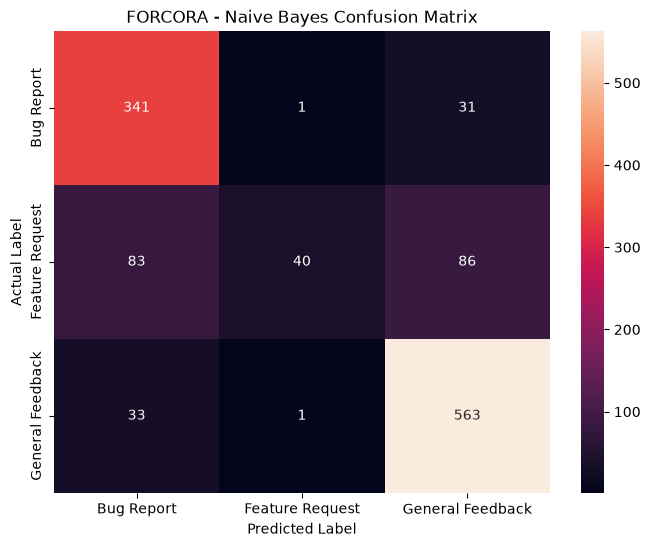

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=nb_model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=nb_model.classes_,
    yticklabels=nb_model.classes_
)

plt.title("FORCORA - Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [26]:
new_reviews = [
    "The app crashes every time I try to upload a photo.",
    "Please add dark mode to the application.",
    "Great app, I use it every day!"
]

new_reviews_vec = vectorizer.transform(new_reviews)

predictions = nb_model.predict(new_reviews_vec)

for review, prediction in zip(new_reviews, predictions):
    print(f"Review: {review}")
    print(f"FORCORA prediction: {prediction}")
    print("-" * 60)

Review: The app crashes every time I try to upload a photo.
FORCORA prediction: Bug Report
------------------------------------------------------------
Review: Please add dark mode to the application.
FORCORA prediction: Feature Request
------------------------------------------------------------
Review: Great app, I use it every day!
FORCORA prediction: General Feedback
------------------------------------------------------------
